In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.5.1+cu121
CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATASET_DIR = Path("dataset")
CSV_PATH = DATASET_DIR / "data.csv"
REAL_DIR = DATASET_DIR / "real"
FAKE_DIR = DATASET_DIR / "fake"

print("Dataset exists:", DATASET_DIR.exists())
print("CSV exists:", CSV_PATH.exists())
print("Real folder exists:", REAL_DIR.exists())
print("Fake folder exists:", FAKE_DIR.exists())

Dataset exists: True
CSV exists: True
Real folder exists: True
Fake folder exists: True


In [3]:
df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())

display(df.head(10))

Dataset shape: (1289, 2)

Columns: ['images_id', 'label']


,images_id,label
0,real_1,real
1,real_10,real
2,real_100,real
3,real_101,real
4,real_102,real
5,real_103,real
6,real_104,real
7,real_105,real
8,real_106,real
9,real_107,real


In [4]:
print("Rows:", len(df))

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Rows: 1289

Data types:
images_id    object
label        object
dtype: object

Missing values:
images_id    0
label        0
dtype: int64

Duplicate rows: 0


In [5]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

real_images = [
    p for p in REAL_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

fake_images = [
    p for p in FAKE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
]

print("Real images :", len(real_images))
print("Fake images :", len(fake_images))
print("Total images:", len(real_images) + len(fake_images))

Real images : 589
Fake images : 700
Total images: 1289


In [6]:
total = len(real_images) + len(fake_images)

print(f"Real: {len(real_images)} ({len(real_images)/total*100:.2f}%)")
print(f"Fake: {len(fake_images)} ({len(fake_images)/total*100:.2f}%)")

Real: 589 (45.69%)
Fake: 700 (54.31%)


In [7]:
all_images = real_images + fake_images

corrupt_images = []
image_sizes = {}

for image_path in all_images:
    try:
        with Image.open(image_path) as img:
            width, height = img.size
            
            image_sizes[(width, height)] = (
                image_sizes.get((width, height), 0) + 1
            )
            
            img.verify()

    except Exception as e:
        corrupt_images.append((image_path, str(e)))

print("Total images  :", len(all_images))
print("Valid images  :", len(all_images) - len(corrupt_images))
print("Corrupt images:", len(corrupt_images))

print("\nImage sizes:")
for size, count in sorted(
    image_sizes.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{size}: {count}")

Total images  : 1289
Valid images  : 1289
Corrupt images: 0

Image sizes:
(300, 300): 1289


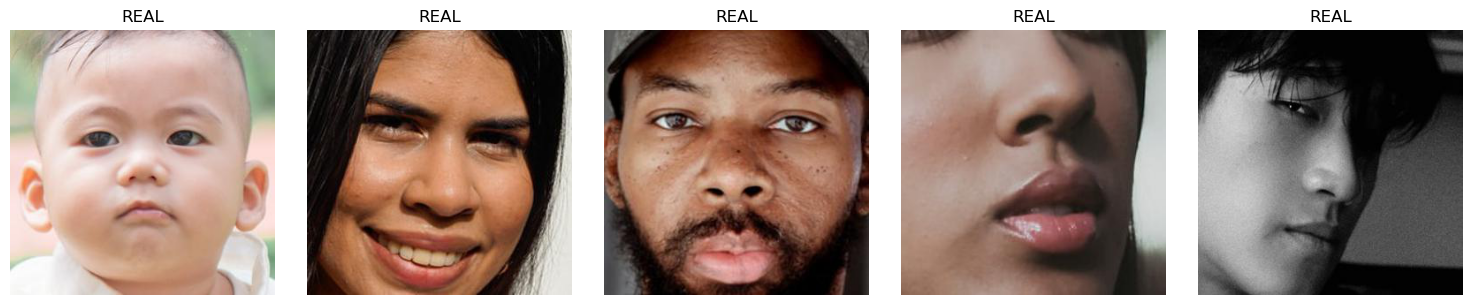

In [8]:
import random

samples = random.sample(real_images, min(5, len(real_images)))

plt.figure(figsize=(15, 3))

for i, image_path in enumerate(samples):
    image = Image.open(image_path).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title("REAL")
    plt.axis("off")

plt.tight_layout()
plt.show()

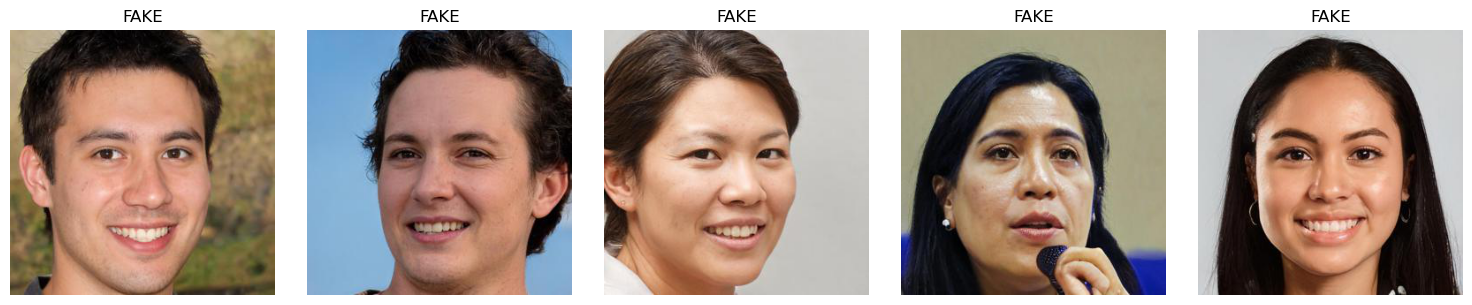

In [9]:
samples = random.sample(fake_images, min(5, len(fake_images)))

plt.figure(figsize=(15, 3))

for i, image_path in enumerate(samples):
    image = Image.open(image_path).convert("RGB")

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title("FAKE")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
print(df["label"].value_counts())

display(df.head(10))

label
fake    700
real    589
Name: count, dtype: int64


,images_id,label
0,real_1,real
1,real_10,real
2,real_100,real
3,real_101,real
4,real_102,real
5,real_103,real
6,real_104,real
7,real_105,real
8,real_106,real
9,real_107,real


In [11]:
from pathlib import Path

def get_image_path(row):
    return DATASET_DIR / row["label"].lower() / f"{row['images_id']}.jpg"

df["image_path"] = df.apply(get_image_path, axis=1)

display(df.head())

,images_id,label,image_path
0,real_1,real,dataset\real\real_1.jpg
1,real_10,real,dataset\real\real_10.jpg
2,real_100,real,dataset\real\real_100.jpg
3,real_101,real,dataset\real\real_101.jpg
4,real_102,real,dataset\real\real_102.jpg


In [12]:
df

,images_id,label,image_path
0,real_1,real,dataset\real\real_1.jpg
1,real_10,real,dataset\real\real_10.jpg
2,real_100,real,dataset\real\real_100.jpg
3,real_101,real,dataset\real\real_101.jpg
4,real_102,real,dataset\real\real_102.jpg
...,...,...,...
1284,fake_95,fake,dataset\fake\fake_95.jpg
1285,fake_96,fake,dataset\fake\fake_96.jpg
1286,fake_97,fake,dataset\fake\fake_97.jpg
1287,fake_98,fake,dataset\fake\fake_98.jpg


In [13]:
print("Existing:", df["image_path"].apply(lambda x: x.exists()).sum())
print("Total:", len(df))

Existing: 1289
Total: 1289


In [14]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 902
Validation: 193
Test: 194


In [15]:
def show_distribution(name, data):
    print(f"\n{name}")
    print("-" * 30)
    print(data["label"].value_counts())
    print()
    print(
        (data["label"].value_counts(normalize=True) * 100)
        .round(2)
        .astype(str) + "%"
    )

show_distribution("TRAIN", train_df)
show_distribution("VALIDATION", val_df)
show_distribution("TEST", test_df)


TRAIN
------------------------------
label
fake    490
real    412
Name: count, dtype: int64

label
fake    54.32%
real    45.68%
Name: proportion, dtype: object

VALIDATION
------------------------------
label
fake    105
real     88
Name: count, dtype: int64

label
fake    54.4%
real    45.6%
Name: proportion, dtype: object

TEST
------------------------------
label
fake    105
real     89
Name: count, dtype: int64

label
fake    54.12%
real    45.88%
Name: proportion, dtype: object


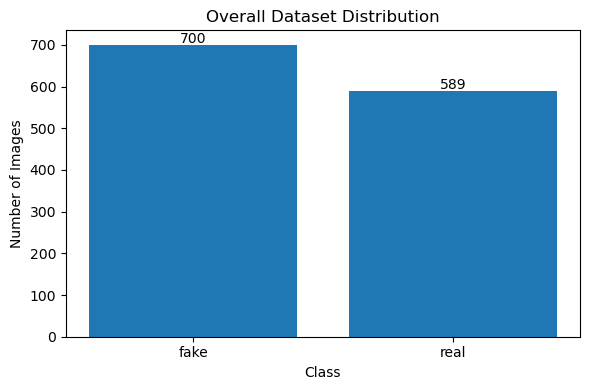

In [16]:
label_counts = df["label"].value_counts()

plt.figure(figsize=(6, 4))

bars = plt.bar(
    label_counts.index,
    label_counts.values
)

plt.title("Overall Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
plt.show()

In [17]:
split_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).T

split_counts

label,fake,real
Train,490,412
Validation,105,88
Test,105,89


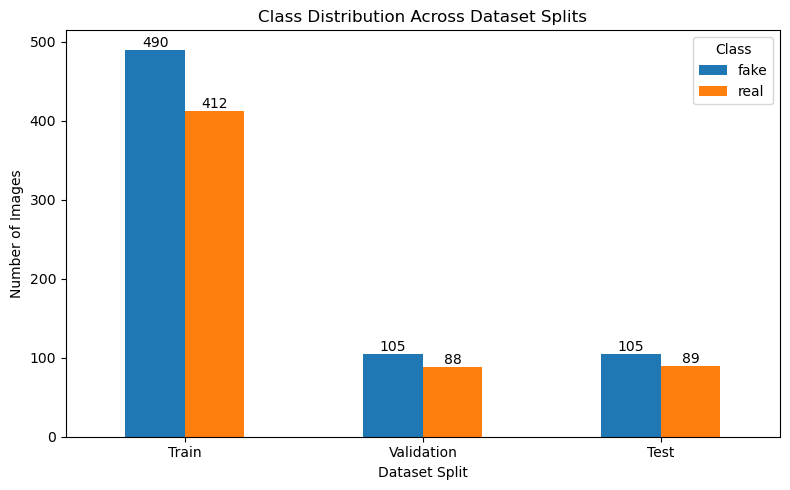

In [18]:
ax = split_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Class")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [19]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from PIL import Image
from tqdm.auto import tqdm

In [20]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [21]:
class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = 1.0 if row["label"].lower() == "fake" else 0.0

        return image, torch.tensor(label, dtype=torch.float32)

In [22]:
train_dataset = DeepfakeDataset(
    train_df,
    transform=transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 902
Validation: 193
Test: 194


In [23]:
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [24]:
train_dataset.dataframe

,images_id,label,image_path
0,real_344,real,dataset\real\real_344.jpg
1,fake_290,fake,dataset\fake\fake_290.jpg
2,fake_483,fake,dataset\fake\fake_483.jpg
3,real_45,real,dataset\real\real_45.jpg
4,fake_98,fake,dataset\fake\fake_98.jpg
...,...,...,...
897,real_223,real,dataset\real\real_223.jpg
898,real_354,real,dataset\real\real_354.jpg
899,real_185,real,dataset\real\real_185.jpg
900,fake_272,fake,dataset\fake\fake_272.jpg


In [25]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Labels:", labels[:8])
print("Min pixel value:", images.min().item())
print("Max pixel value:", images.max().item())

Image batch shape: torch.Size([8, 3, 300, 300])
Label batch shape: torch.Size([8])
Labels: 

tensor([1., 0., 0., 0., 1., 1., 0., 0.])
Min pixel value: -2.1179039478302
Max pixel value: 2.640000104904175


In [26]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [27]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load ImageNet pretrained ResNet50
weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)

# Freeze pretrained CNN backbone
for param in model.parameters():
    param.requires_grad = False

# Original feature vector size
num_features = model.fc.in_features

print("CNN feature vector size:", num_features)

# Replace ImageNet 1000-class classifier
# with our binary Real/Fake classifier
model.fc = nn.Linear(num_features, 1)

model = model.to(device)

print(model.fc)

CNN feature vector size: 2048
Linear(in_features=2048, out_features=1, bias=True)


In [28]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [29]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3
)

In [30]:
EPOCHS = 5

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(EPOCHS):

    # ------------------
    # TRAIN
    # ------------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(images).squeeze(1)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).float()

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_accuracy = train_correct / train_total


    # ------------------
    # VALIDATION
    # ------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            logits = model(images).squeeze(1)

            loss = criterion(logits, labels)

            val_loss += loss.item() * images.size(0)

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).float()

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)


    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 1/5:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 0.4407 | Train Acc: 0.8847 | Val Loss: 0.2607 | Val Acc: 0.9741


Epoch 2/5:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 2/5 | Train Loss: 0.2293 | Train Acc: 0.9634 | Val Loss: 0.1967 | Val Acc: 0.9534


Epoch 3/5:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 3/5 | Train Loss: 0.1815 | Train Acc: 0.9634 | Val Loss: 0.1481 | Val Acc: 0.9793


Epoch 4/5:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 0.1531 | Train Acc: 0.9623 | Val Loss: 0.1051 | Val Acc: 0.9896


Epoch 5/5:   0%|          | 0/113 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 0.1378 | Train Acc: 0.9656 | Val Loss: 0.0891 | Val Acc: 0.9896


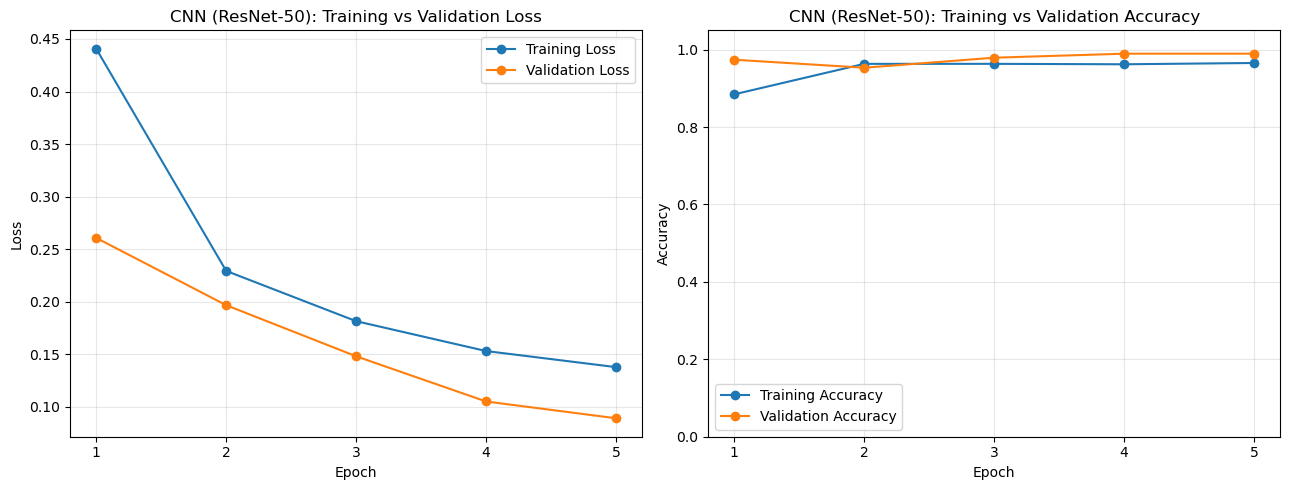

In [31]:
def plot_training_history(history, model_name):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(epochs, history["train_loss"], marker="o", label="Training Loss")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation Loss")
    axes[0].set_title(f"{model_name}: Training vs Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_xticks(list(epochs))
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
    axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")
    axes[1].set_title(f"{model_name}: Training vs Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_xticks(list(epochs))
    axes[1].set_ylim(0, 1.05)
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history, "CNN (ResNet-50)")

Testing CNN (ResNet-50):   0%|          | 0/25 [00:00<?, ?it/s]

CNN (ResNet-50) Test Loss:      0.1218
CNN (ResNet-50) Test Accuracy:  0.9588
CNN (ResNet-50) Test Precision: 0.9369
CNN (ResNet-50) Test Recall:    0.9905
CNN (ResNet-50) Test F1 Score:  0.9630

Classification report:
              precision    recall  f1-score   support

        Real       0.99      0.92      0.95        89
        Fake       0.94      0.99      0.96       105

    accuracy                           0.96       194
   macro avg       0.96      0.96      0.96       194
weighted avg       0.96      0.96      0.96       194



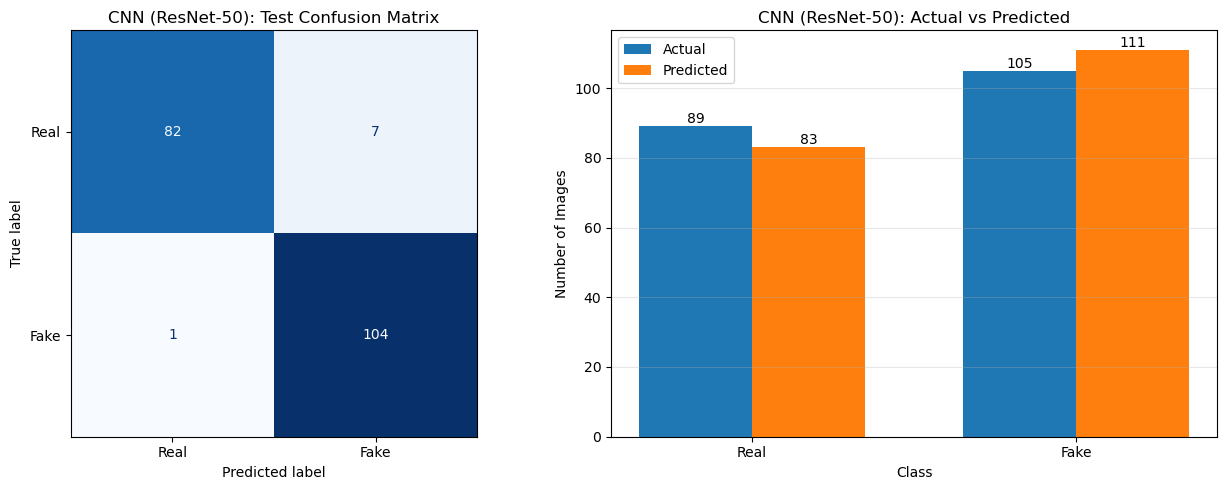

In [32]:
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

def move_to_device(inputs, device):
    if isinstance(inputs, (list, tuple)):
        return tuple(item.to(device, non_blocking=True) for item in inputs)
    return inputs.to(device, non_blocking=True)

def evaluate_model(model, data_loader, dataset, criterion, device, model_name):
    model.eval()
    labels_all, predictions_all, probabilities_all = [], [], []
    total_loss = 0.0

    with torch.no_grad():
        for inputs, labels in tqdm(data_loader, desc=f"Testing {model_name}"):
            inputs = move_to_device(inputs, device)
            labels = labels.to(device, non_blocking=True)
            logits = model(inputs).squeeze(1)
            total_loss += criterion(logits, labels).item() * labels.size(0)
            probabilities = torch.sigmoid(logits)
            predictions = (probabilities >= 0.5).long()
            labels_all.extend(labels.long().cpu().tolist())
            predictions_all.extend(predictions.cpu().tolist())
            probabilities_all.extend(probabilities.cpu().tolist())

    results = {
        "model_name": model_name,
        "loss": total_loss / len(dataset),
        "accuracy": accuracy_score(labels_all, predictions_all),
        "precision": precision_score(labels_all, predictions_all, zero_division=0),
        "recall": recall_score(labels_all, predictions_all, zero_division=0),
        "f1": f1_score(labels_all, predictions_all, zero_division=0),
        "labels": labels_all,
        "predictions": predictions_all,
        "probabilities": probabilities_all
    }

    print(f"{model_name} Test Loss:      {results['loss']:.4f}")
    print(f"{model_name} Test Accuracy:  {results['accuracy']:.4f}")
    print(f"{model_name} Test Precision: {results['precision']:.4f}")
    print(f"{model_name} Test Recall:    {results['recall']:.4f}")
    print(f"{model_name} Test F1 Score:  {results['f1']:.4f}")
    print("\nClassification report:")
    print(classification_report(labels_all, predictions_all, target_names=["Real", "Fake"], zero_division=0))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    cm = confusion_matrix(labels_all, predictions_all, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Real", "Fake"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False
    )
    axes[0].set_title(f"{model_name}: Test Confusion Matrix")

    actual_counts = [labels_all.count(0), labels_all.count(1)]
    predicted_counts = [predictions_all.count(0), predictions_all.count(1)]
    x = np.arange(2)
    width = 0.35
    axes[1].bar(x - width / 2, actual_counts, width, label="Actual")
    axes[1].bar(x + width / 2, predicted_counts, width, label="Predicted")
    axes[1].set_title(f"{model_name}: Actual vs Predicted")
    axes[1].set_xlabel("Class")
    axes[1].set_ylabel("Number of Images")
    axes[1].set_xticks(x, ["Real", "Fake"])
    axes[1].legend()
    axes[1].grid(axis="y", alpha=0.3)
    for container in axes[1].containers:
        axes[1].bar_label(container)

    plt.tight_layout()
    plt.show()
    return results

cnn_test_results = evaluate_model(
    model, test_loader, test_dataset, criterion, device, "CNN (ResNet-50)"
)

CNN (ResNet-50) incorrect predictions: 8
Real predicted as Fake: 7
Fake predicted as Real: 1


,images_id,image_path,actual_label,predicted_label,fake_probability
14,real_422,dataset\real\real_422.jpg,Real,Fake,0.862367
25,real_493,dataset\real\real_493.jpg,Real,Fake,0.685825
98,real_193,dataset\real\real_193.jpg,Real,Fake,0.915091
126,fake_447,dataset\fake\fake_447.jpg,Fake,Real,0.343407
130,real_160,dataset\real\real_160.jpg,Real,Fake,0.651146
144,real_361,dataset\real\real_361.jpg,Real,Fake,0.537273
147,real_511,dataset\real\real_511.jpg,Real,Fake,0.552291
167,real_121,dataset\real\real_121.jpg,Real,Fake,0.625003


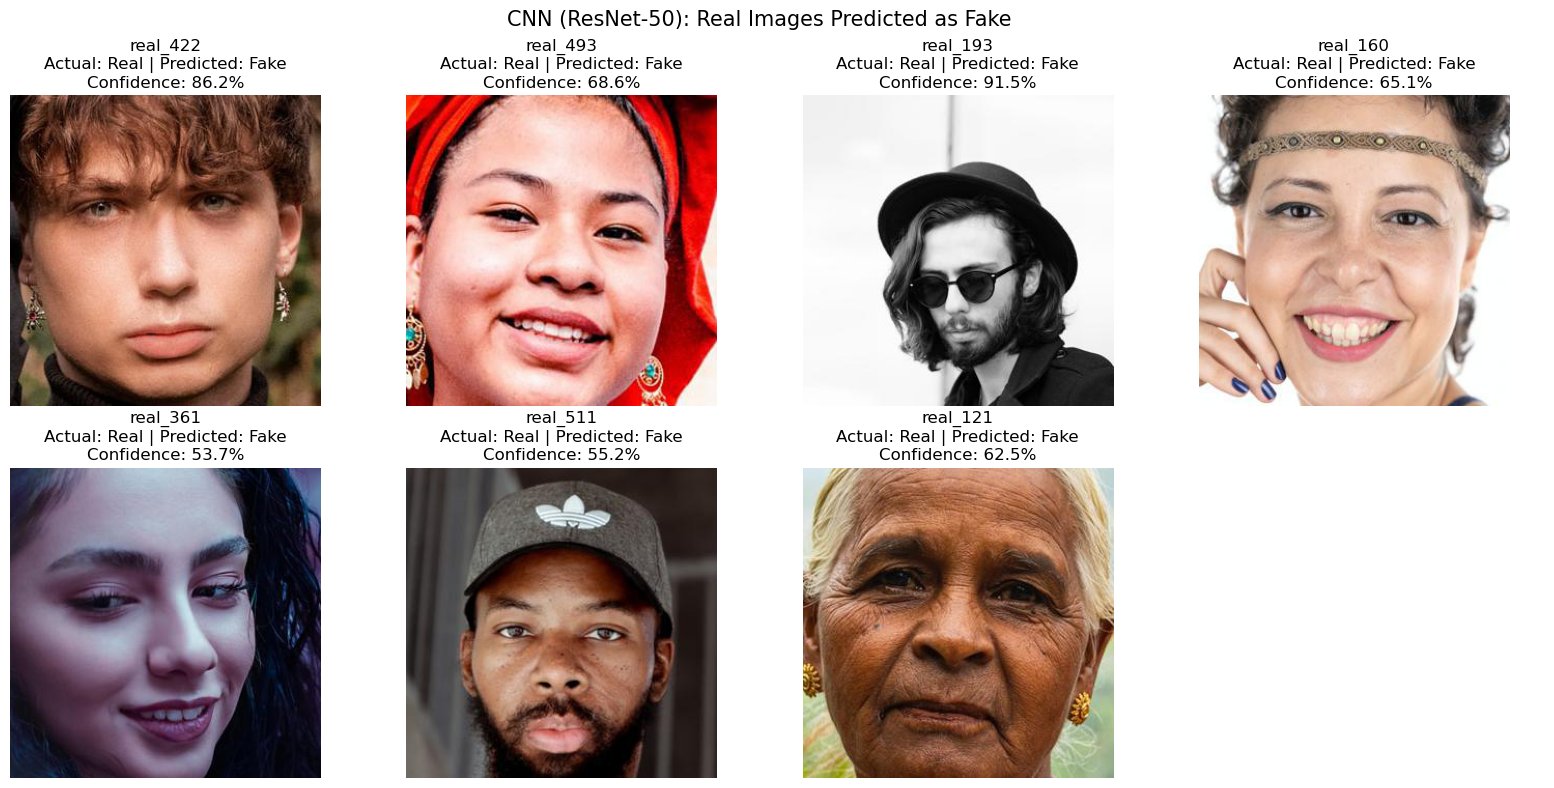

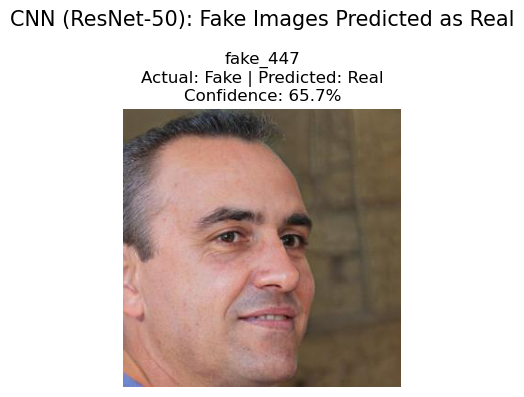

In [33]:
def inspect_misclassified_images(evaluation, dataset):
    # The evaluation loader must use shuffle=False so rows stay aligned.
    prediction_results = dataset.dataframe.copy().reset_index(drop=True)
    labels = np.array(evaluation["labels"])
    predictions = np.array(evaluation["predictions"])
    prediction_results["actual_label"] = np.where(labels == 1, "Fake", "Real")
    prediction_results["predicted_label"] = np.where(predictions == 1, "Fake", "Real")
    prediction_results["fake_probability"] = evaluation["probabilities"]
    prediction_results["correct"] = labels == predictions

    incorrect = prediction_results.loc[~prediction_results["correct"]].copy()
    real_as_fake = incorrect.query("actual_label == 'Real' and predicted_label == 'Fake'")
    fake_as_real = incorrect.query("actual_label == 'Fake' and predicted_label == 'Real'")
    model_name = evaluation["model_name"]

    print(f"{model_name} incorrect predictions: {len(incorrect)}")
    print(f"Real predicted as Fake: {len(real_as_fake)}")
    print(f"Fake predicted as Real: {len(fake_as_real)}")
    display(incorrect[["images_id", "image_path", "actual_label", "predicted_label", "fake_probability"]])

    def show_group(data, title):
        if data.empty:
            print(f"{title}: none")
            return
        columns = min(4, len(data))
        rows = int(np.ceil(len(data) / columns))
        fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * rows), squeeze=False)
        for ax, (_, result) in zip(axes.flat, data.iterrows()):
            with Image.open(result["image_path"]) as image:
                ax.imshow(image.convert("RGB"))
            confidence = (result["fake_probability"] if result["predicted_label"] == "Fake"
                          else 1 - result["fake_probability"])
            ax.set_title(
                f"{result['images_id']}\nActual: {result['actual_label']} | "
                f"Predicted: {result['predicted_label']}\nConfidence: {confidence:.1%}"
            )
            ax.axis("off")
        for ax in axes.flat[len(data):]:
            ax.axis("off")
        fig.suptitle(f"{model_name}: {title}", fontsize=15)
        plt.tight_layout()
        plt.show()

    show_group(real_as_fake, "Real Images Predicted as Fake")
    show_group(fake_as_real, "Fake Images Predicted as Real")
    return incorrect

cnn_misclassified = inspect_misclassified_images(cnn_test_results, test_dataset)

In [34]:
from torchvision import transforms
from torchvision.models import ViT_B_16_Weights

vit_weights = ViT_B_16_Weights.DEFAULT

vit_transform = transforms.Compose([
    transforms.Resize((224, 224)),   # whole image, NO crop
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [35]:
vit_train_dataset = DeepfakeDataset(
    train_df,
    transform=vit_transform
)

vit_val_dataset = DeepfakeDataset(
    val_df,
    transform=vit_transform
)

vit_test_dataset = DeepfakeDataset(
    test_df,
    transform=vit_transform
)

In [36]:
VIT_BATCH_SIZE = 4

vit_train_loader = DataLoader(
    vit_train_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

vit_val_loader = DataLoader(
    vit_val_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

vit_test_loader = DataLoader(
    vit_test_dataset,
    batch_size=VIT_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [37]:
images, labels = next(iter(vit_train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([4, 3, 224, 224])
Labels: torch.Size([4])


In [38]:
import torch.nn as nn
from torchvision.models import vit_b_16, ViT_B_16_Weights

vit_weights = ViT_B_16_Weights.DEFAULT

vit_model = vit_b_16(weights=vit_weights)

In [39]:
for param in vit_model.parameters():
    param.requires_grad = False

print(vit_model.heads)

Sequential(
  (head): Linear(in_features=768, out_features=1000, bias=True)
)


In [40]:
num_features = vit_model.heads.head.in_features

print("ViT feature size:", num_features)

vit_model.heads.head = nn.Linear(
    num_features,
    1
)

vit_model = vit_model.to(device)

ViT feature size: 768


In [41]:
total_params = sum(
    p.numel() for p in vit_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in vit_model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Total parameters: 85,799,425
Trainable parameters: 769


In [42]:
images, labels = next(iter(vit_train_loader))

images = images.to(device)

with torch.no_grad():
    logits = vit_model(images).squeeze(1)
    probabilities = torch.sigmoid(logits)

print("Input shape :", images.shape)
print("Output shape:", logits.shape)

print("\nLogits:")
print(logits)

print("\nP(Fake):")
print(probabilities)

Input shape : torch.Size([4, 3, 224, 224])
Output shape: torch.Size([4])

Logits:


tensor([ 0.3743,  0.0162, -0.3177,  0.5154], device='cuda:0')

P(Fake):
tensor([0.5925, 0.5041, 0.4212, 0.6261], device='cuda:0')


In [43]:
vit_criterion = nn.BCEWithLogitsLoss()

vit_optimizer = torch.optim.AdamW(
    vit_model.heads.head.parameters(),
    lr=1e-3
)

In [44]:
VIT_EPOCHS = 5

vit_history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(VIT_EPOCHS):

    # =====================
    # TRAIN
    # =====================

    vit_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    progress = tqdm(
        vit_train_loader,
        desc=f"ViT Epoch {epoch+1}/{VIT_EPOCHS}"
    )

    for images, labels in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        vit_optimizer.zero_grad()

        logits = vit_model(images).squeeze(1)

        loss = vit_criterion(
            logits,
            labels
        )

        loss.backward()
        vit_optimizer.step()

        train_loss += (
            loss.item() * images.size(0)
        )

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_accuracy = (
        train_correct / train_total
    )

    # =====================
    # VALIDATION
    # =====================

    vit_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in vit_val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = vit_model(
                images
            ).squeeze(1)

            loss = vit_criterion(
                logits,
                labels
            )

            val_loss += (
                loss.item() *
                images.size(0)
            )

            probabilities = torch.sigmoid(
                logits
            )

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = (
        val_correct / val_total
    )

    vit_history["train_loss"].append(train_loss)
    vit_history["val_loss"].append(val_loss)
    vit_history["train_accuracy"].append(train_accuracy)
    vit_history["val_accuracy"].append(val_accuracy)

    print(
        f"ViT Epoch {epoch+1}/{VIT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

ViT Epoch 1/5:   0%|          | 0/226 [00:00<?, ?it/s]

ViT Epoch 1/5 | Train Loss: 0.2775 | Train Acc: 0.9069 | Val Loss: 0.1958 | Val Acc: 0.9326


ViT Epoch 2/5:   0%|          | 0/226 [00:00<?, ?it/s]

ViT Epoch 2/5 | Train Loss: 0.1229 | Train Acc: 0.9690 | Val Loss: 0.1374 | Val Acc: 0.9534


ViT Epoch 3/5:   0%|          | 0/226 [00:00<?, ?it/s]

ViT Epoch 3/5 | Train Loss: 0.0824 | Train Acc: 0.9845 | Val Loss: 0.1121 | Val Acc: 0.9637


ViT Epoch 4/5:   0%|          | 0/226 [00:00<?, ?it/s]

ViT Epoch 4/5 | Train Loss: 0.0620 | Train Acc: 0.9889 | Val Loss: 0.0969 | Val Acc: 0.9741


ViT Epoch 5/5:   0%|          | 0/226 [00:00<?, ?it/s]

ViT Epoch 5/5 | Train Loss: 0.0497 | Train Acc: 0.9933 | Val Loss: 0.0885 | Val Acc: 0.9741


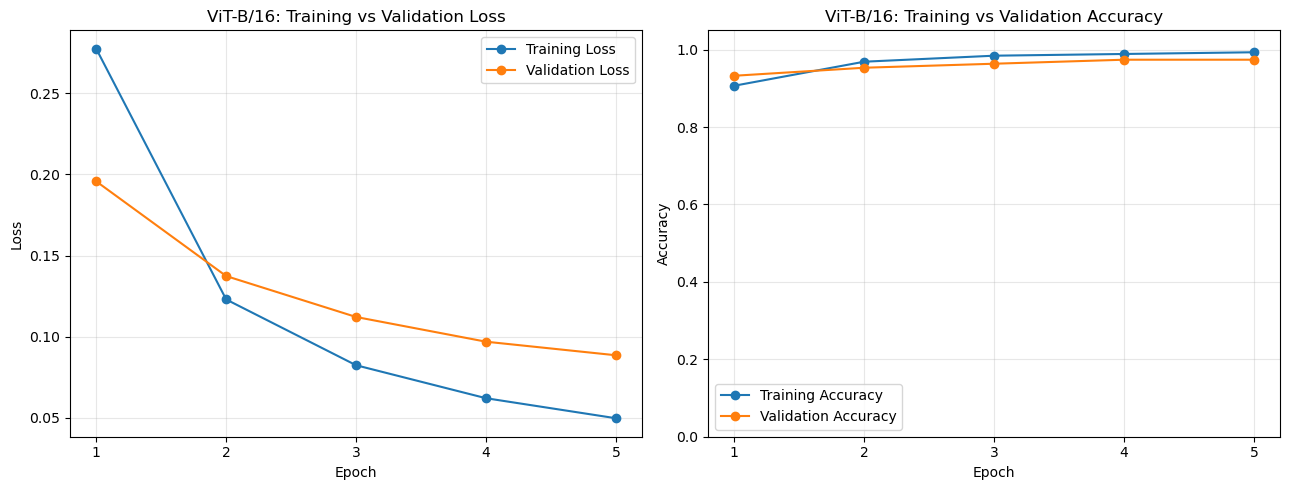

Testing ViT-B/16:   0%|          | 0/49 [00:00<?, ?it/s]

ViT-B/16 Test Loss:      0.0718
ViT-B/16 Test Accuracy:  0.9897
ViT-B/16 Test Precision: 0.9813
ViT-B/16 Test Recall:    1.0000
ViT-B/16 Test F1 Score:  0.9906

Classification report:
              precision    recall  f1-score   support

        Real       1.00      0.98      0.99        89
        Fake       0.98      1.00      0.99       105

    accuracy                           0.99       194
   macro avg       0.99      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194



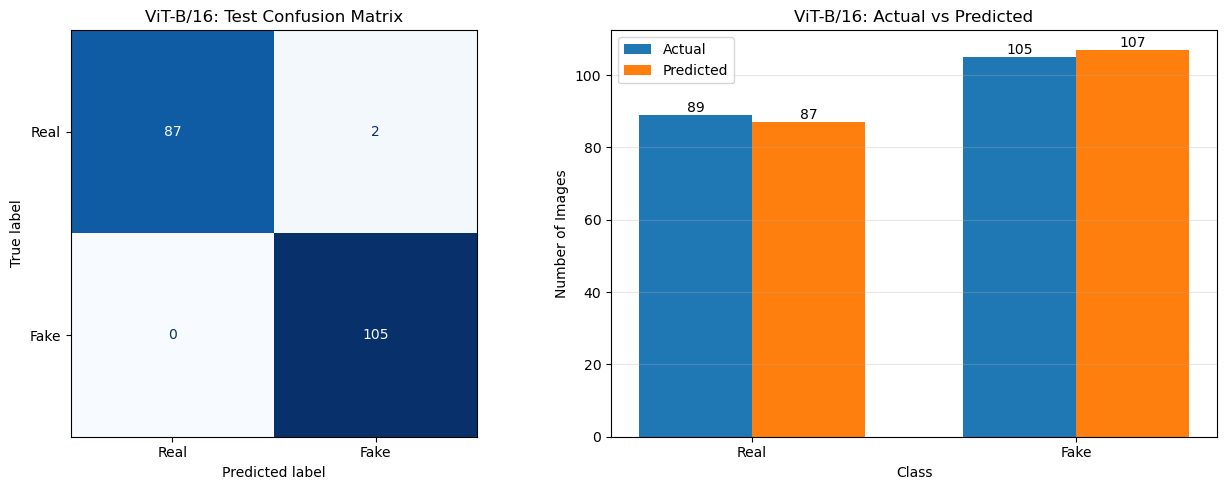

ViT-B/16 incorrect predictions: 2
Real predicted as Fake: 2
Fake predicted as Real: 0


,images_id,image_path,actual_label,predicted_label,fake_probability
98,real_193,dataset\real\real_193.jpg,Real,Fake,0.826520
190,real_432,dataset\real\real_432.jpg,Real,Fake,0.595171


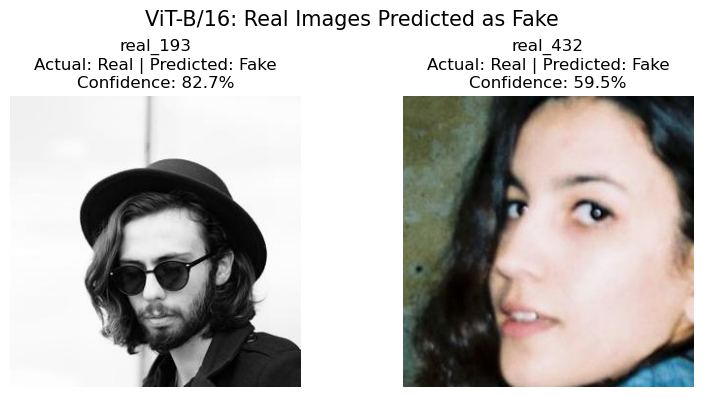

Fake Images Predicted as Real: none


In [45]:
# Reuse the methods from cells 30, 31 and 32 for ViT.
plot_training_history(vit_history, "ViT-B/16")

vit_test_results = evaluate_model(
    vit_model, vit_test_loader, vit_test_dataset,
    vit_criterion, device, "ViT-B/16"
)

vit_misclassified = inspect_misclassified_images(
    vit_test_results, vit_test_dataset
)

In [46]:
class FusionDataset(Dataset):
    """Load one source image and prepare it for both feature extractors."""

    def __init__(self, dataframe, cnn_transform, vit_transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.cnn_transform = cnn_transform
        self.vit_transform = vit_transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            cnn_image = self.cnn_transform(image)
            vit_image = self.vit_transform(image)
        label = 1.0 if row["label"].lower() == "fake" else 0.0
        return (cnn_image, vit_image), torch.tensor(label, dtype=torch.float32)

fusion_train_dataset = FusionDataset(train_df, transform, vit_transform)
fusion_val_dataset = FusionDataset(val_df, transform, vit_transform)
fusion_test_dataset = FusionDataset(test_df, transform, vit_transform)

FUSION_BATCH_SIZE = 4
fusion_train_loader = DataLoader(fusion_train_dataset, batch_size=FUSION_BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
fusion_val_loader = DataLoader(fusion_val_dataset, batch_size=FUSION_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
fusion_test_loader = DataLoader(fusion_test_dataset, batch_size=FUSION_BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("Fusion train/validation/test:", len(fusion_train_dataset), len(fusion_val_dataset), len(fusion_test_dataset))

Fusion train/validation/test: 902 193 194


In [47]:
class FusionClassifier(nn.Module):
    """CNN features + ViT features -> concatenate -> binary logit."""

    def __init__(self, trained_cnn, trained_vit):
        super().__init__()
        self.cnn_features = nn.Sequential(*list(trained_cnn.children())[:-1])
        self.vit_features = trained_vit

        for parameter in self.cnn_features.parameters():
            parameter.requires_grad = False
        for parameter in self.vit_features.parameters():
            parameter.requires_grad = False

        self.cnn_feature_size = trained_cnn.fc.in_features       # 2048
        self.vit_feature_size = trained_vit.heads.head.in_features  # 768
        self.fused_feature_size = self.cnn_feature_size + self.vit_feature_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(self.fused_feature_size),
            nn.Dropout(0.30),
            nn.Linear(self.fused_feature_size, 1)
        )

    def train(self, mode=True):
        super().train(mode)
        # Frozen backbones stay deterministic; only the fusion classifier trains.
        self.cnn_features.eval()
        self.vit_features.eval()
        return self

    def forward(self, inputs):
        cnn_images, vit_images = inputs
        with torch.no_grad():
            cnn_vector = self.cnn_features(cnn_images).flatten(1)

            vit_tokens = self.vit_features._process_input(vit_images)
            batch_size = vit_tokens.shape[0]
            class_token = self.vit_features.class_token.expand(batch_size, -1, -1)
            vit_tokens = torch.cat([class_token, vit_tokens], dim=1)
            vit_vector = self.vit_features.encoder(vit_tokens)[:, 0]

        fused_vector = torch.cat([cnn_vector, vit_vector], dim=1)
        return self.classifier(fused_vector)

fusion_model = FusionClassifier(model, vit_model).to(device)
fusion_criterion = nn.BCEWithLogitsLoss()
fusion_optimizer = torch.optim.AdamW(fusion_model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)

print(f"CNN feature vector: {fusion_model.cnn_feature_size}")
print(f"ViT feature vector: {fusion_model.vit_feature_size}")
print(f"Concatenated vector: {fusion_model.fused_feature_size}")
print("Trainable fusion parameters:", sum(p.numel() for p in fusion_model.parameters() if p.requires_grad))

CNN feature vector: 2048
ViT feature vector: 768
Concatenated vector: 2816
Trainable fusion parameters: 8449


In [48]:
def train_binary_model(model, train_loader, val_loader, criterion, optimizer, device, epochs, model_name):
    history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        train_loss = train_correct = train_total = 0

        for inputs, labels in tqdm(train_loader, desc=f"{model_name} Epoch {epoch + 1}/{epochs}"):
            inputs = move_to_device(inputs, device)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad()
            logits = model(inputs).squeeze(1)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * labels.size(0)
            train_correct += ((torch.sigmoid(logits) >= 0.5).float() == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_loss = val_correct = val_total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = move_to_device(inputs, device)
                labels = labels.to(device, non_blocking=True)
                logits = model(inputs).squeeze(1)
                loss = criterion(logits, labels)
                val_loss += loss.item() * labels.size(0)
                val_correct += ((torch.sigmoid(logits) >= 0.5).float() == labels).sum().item()
                val_total += labels.size(0)

        epoch_values = (train_loss / train_total, val_loss / val_total,
                        train_correct / train_total, val_correct / val_total)
        for key, value in zip(history, epoch_values):
            history[key].append(value)

        print(
            f"Epoch {epoch + 1}/{epochs} | Train Loss: {epoch_values[0]:.4f} | "
            f"Train Acc: {epoch_values[2]:.4f} | Val Loss: {epoch_values[1]:.4f} | "
            f"Val Acc: {epoch_values[3]:.4f}"
        )

    return history

CNN + ViT Fusion Epoch 1/4:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 1/4 | Train Loss: 0.1263 | Train Acc: 0.9612 | Val Loss: 0.0556 | Val Acc: 0.9896


CNN + ViT Fusion Epoch 2/4:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 2/4 | Train Loss: 0.0235 | Train Acc: 0.9967 | Val Loss: 0.0392 | Val Acc: 0.9845


CNN + ViT Fusion Epoch 3/4:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 3/4 | Train Loss: 0.0151 | Train Acc: 0.9978 | Val Loss: 0.0305 | Val Acc: 0.9896


CNN + ViT Fusion Epoch 4/4:   0%|          | 0/226 [00:00<?, ?it/s]

Epoch 4/4 | Train Loss: 0.0062 | Train Acc: 1.0000 | Val Loss: 0.0299 | Val Acc: 0.9845


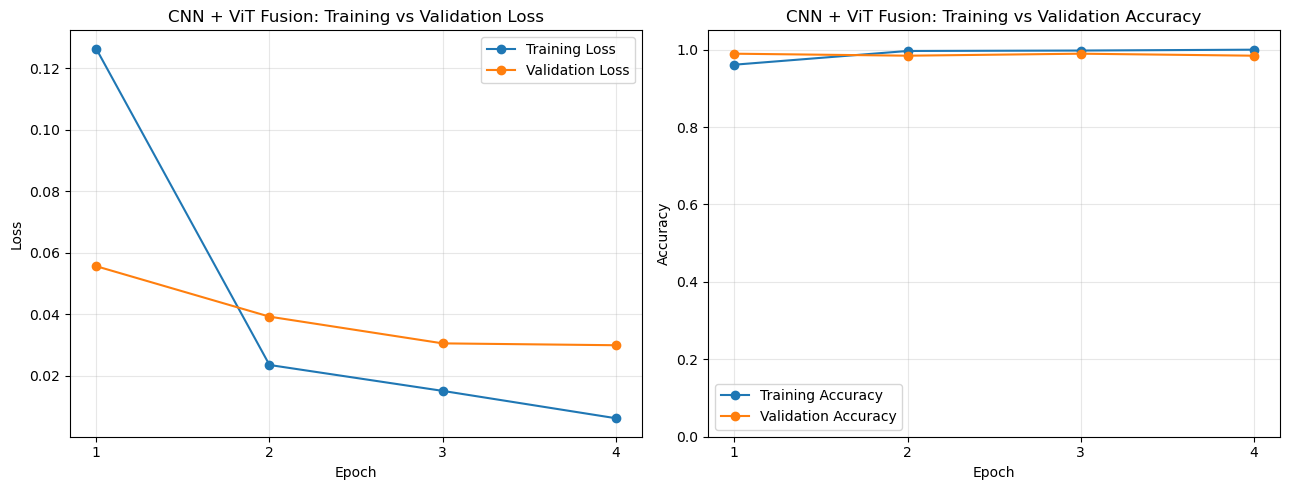

Testing CNN + ViT Fusion:   0%|          | 0/49 [00:00<?, ?it/s]

CNN + ViT Fusion Test Loss:      0.0344
CNN + ViT Fusion Test Accuracy:  0.9948
CNN + ViT Fusion Test Precision: 0.9906
CNN + ViT Fusion Test Recall:    1.0000
CNN + ViT Fusion Test F1 Score:  0.9953

Classification report:
              precision    recall  f1-score   support

        Real       1.00      0.99      0.99        89
        Fake       0.99      1.00      1.00       105

    accuracy                           0.99       194
   macro avg       1.00      0.99      0.99       194
weighted avg       0.99      0.99      0.99       194



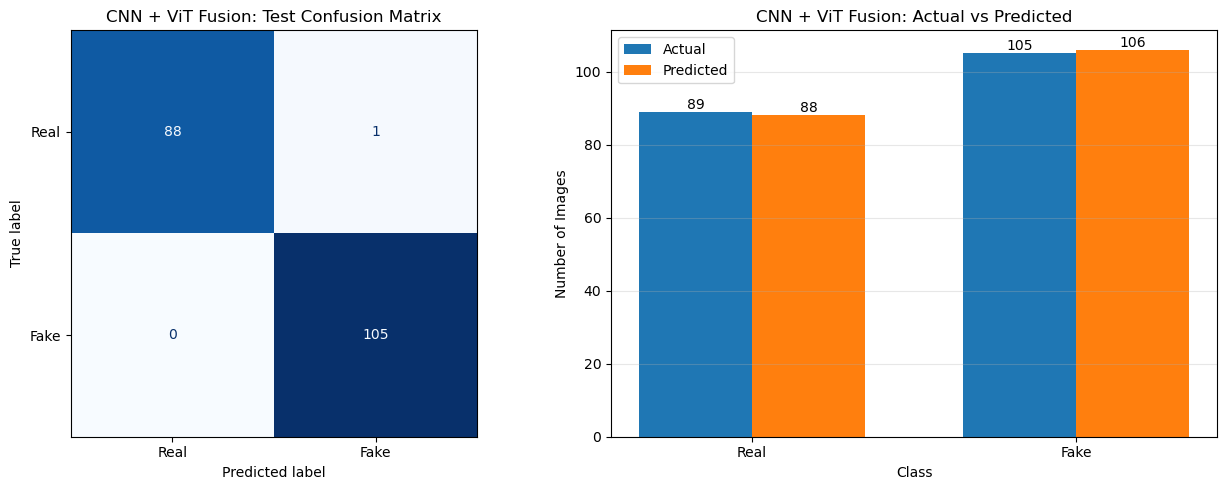

CNN + ViT Fusion incorrect predictions: 1
Real predicted as Fake: 1
Fake predicted as Real: 0


,images_id,image_path,actual_label,predicted_label,fake_probability
98,real_193,dataset\real\real_193.jpg,Real,Fake,0.928657


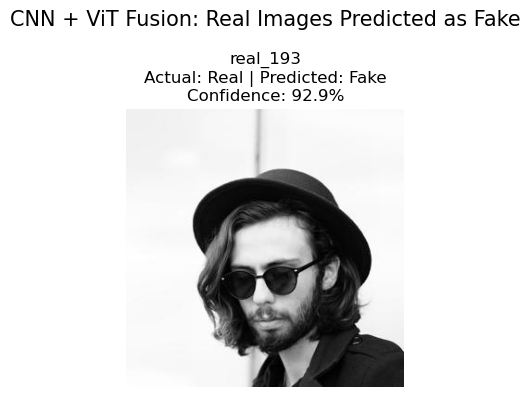

Fake Images Predicted as Real: none


In [49]:
FUSION_EPOCHS = 4
fusion_history = train_binary_model(
    fusion_model, fusion_train_loader, fusion_val_loader, fusion_criterion,
    fusion_optimizer, device, FUSION_EPOCHS, "CNN + ViT Fusion"
)

plot_training_history(fusion_history, "CNN + ViT Fusion")
fusion_test_results = evaluate_model(
    fusion_model, fusion_test_loader, fusion_test_dataset,
    fusion_criterion, device, "CNN + ViT Fusion"
)
fusion_misclassified = inspect_misclassified_images(
    fusion_test_results, fusion_test_dataset
)

Fusion inference:   0%|          | 0/3 [00:00<?, ?it/s]

,filename,prediction,confidence,fake_probability
0,Test1.jpg,Fake,61.11%,61.11%
1,Test2.jpg,Fake,99.44%,99.44%
2,Test3.jpg,Real,60.89%,39.11%


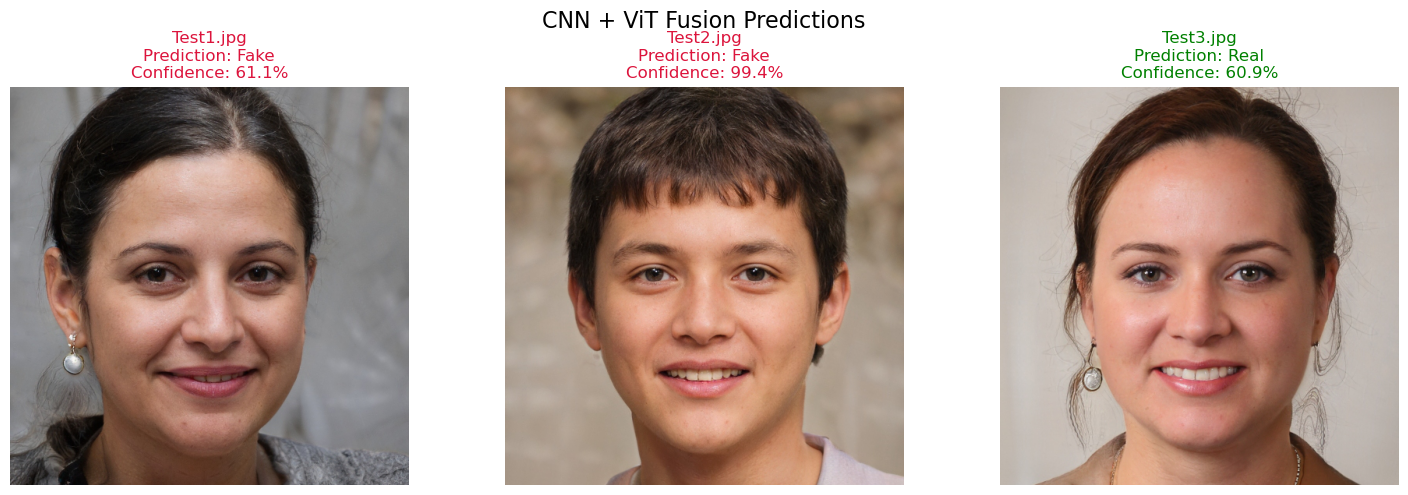

In [50]:
def predict_image_folder(model, folder, cnn_transform, vit_transform, device):
    folder = Path(folder)
    image_paths = sorted(
        path for path in folder.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    if not image_paths:
        raise ValueError(f"No supported images found in {folder}")

    model.eval()
    rows = []
    with torch.no_grad():
        for image_path in tqdm(image_paths, desc="Fusion inference"):
            with Image.open(image_path) as image:
                rgb_image = image.convert("RGB")
                cnn_image = cnn_transform(rgb_image).unsqueeze(0).to(device)
                vit_image = vit_transform(rgb_image).unsqueeze(0).to(device)

            logit = model((cnn_image, vit_image)).squeeze()
            fake_probability = torch.sigmoid(logit).item()
            predicted_label = "Fake" if fake_probability >= 0.5 else "Real"
            confidence = fake_probability if predicted_label == "Fake" else 1 - fake_probability
            rows.append({
                "filename": image_path.name,
                "prediction": predicted_label,
                "confidence": confidence,
                "fake_probability": fake_probability,
                "image_path": image_path
            })

    results = pd.DataFrame(rows)
    display(results[["filename", "prediction", "confidence", "fake_probability"]].style.format({
        "confidence": "{:.2%}", "fake_probability": "{:.2%}"
    }))

    columns = min(3, len(results))
    plot_rows = int(np.ceil(len(results) / columns))
    fig, axes = plt.subplots(plot_rows, columns, figsize=(5 * columns, 5 * plot_rows), squeeze=False)
    for ax, (_, result) in zip(axes.flat, results.iterrows()):
        with Image.open(result["image_path"]) as image:
            ax.imshow(image.convert("RGB"))
        color = "crimson" if result["prediction"] == "Fake" else "green"
        ax.set_title(
            f"{result['filename']}\nPrediction: {result['prediction']}\n"
            f"Confidence: {result['confidence']:.1%}", color=color
        )
        ax.axis("off")
    for ax in axes.flat[len(results):]:
        ax.axis("off")
    plt.suptitle("CNN + ViT Fusion Predictions", fontsize=16)
    plt.tight_layout()
    plt.show()
    return results

fake_images_results = predict_image_folder(
    fusion_model, "fakeImages", transform, vit_transform, device
)